In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
df = pd.read_csv(r"C:\Users\lokes\Downloads\PRCP-1009-CellphonePrice\Data\datasets_11167_15520_train.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


In [7]:
print("Dataset Information")
print("===================")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information
Rows: 2000
Columns: 21

Column Names:
['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi', 'price_range']


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [27]:
print("Missing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:


,Missing Values
battery_power,0
blue,0
clock_speed,0
dual_sim,0
fc,0
four_g,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0



Duplicate Rows:
0


In [28]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


In [29]:
print("Price Range Distribution:")
print(df["price_range"].value_counts().sort_index())

print("\nPercentage Distribution:")
print((df["price_range"].value_counts(normalize=True).sort_index() * 100).round(2))

Price Range Distribution:
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64

Percentage Distribution:
price_range
0    25.0
1    25.0
2    25.0
3    25.0
Name: proportion, dtype: float64


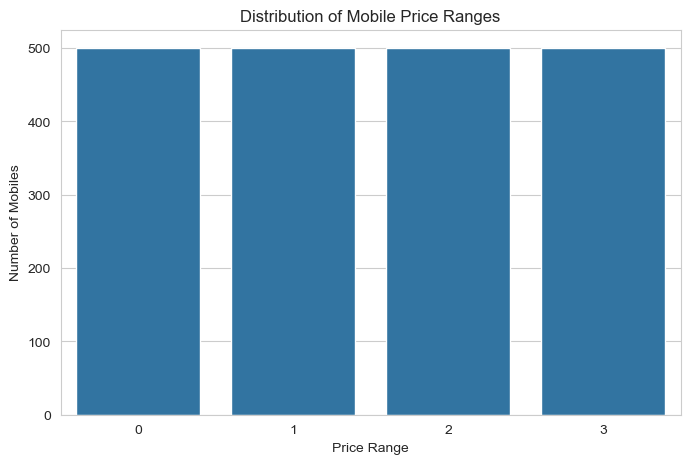

In [30]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="price_range")

plt.title("Distribution of Mobile Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("Number of Mobiles")
plt.show()

In [31]:
for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

battery_power: 1094 unique values
blue: 2 unique values
clock_speed: 26 unique values
dual_sim: 2 unique values
fc: 20 unique values
four_g: 2 unique values
int_memory: 63 unique values
m_dep: 10 unique values
mobile_wt: 121 unique values
n_cores: 8 unique values
pc: 21 unique values
px_height: 1137 unique values
px_width: 1109 unique values
ram: 1562 unique values
sc_h: 15 unique values
sc_w: 19 unique values
talk_time: 19 unique values
three_g: 2 unique values
touch_screen: 2 unique values
wifi: 2 unique values
price_range: 4 unique values


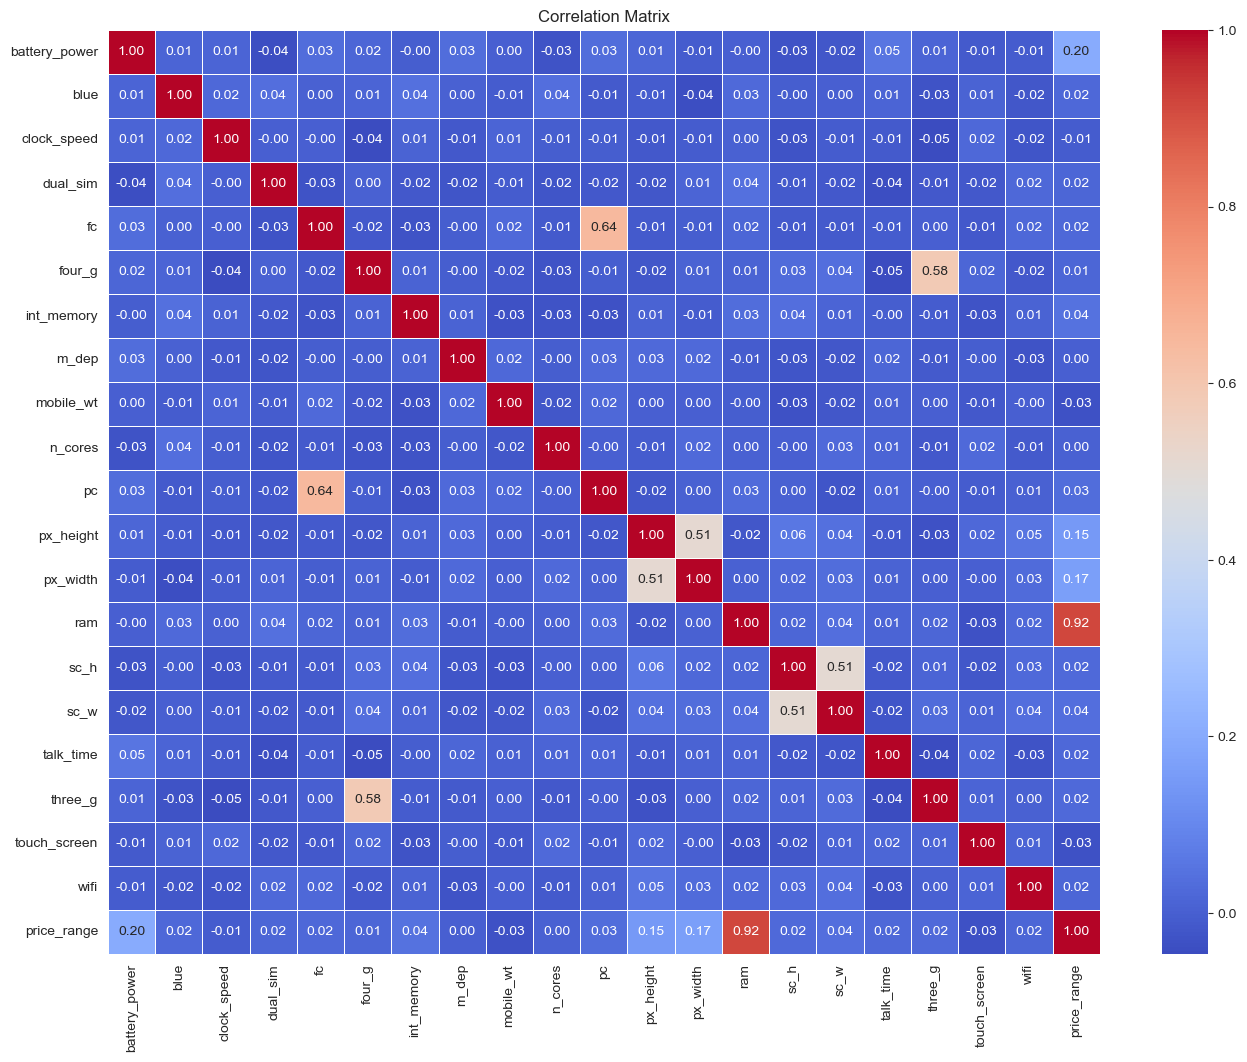

In [32]:
plt.figure(figsize=(16, 12))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

In [33]:
price_correlation = (
    df.corr(numeric_only=True)["price_range"]
    .drop("price_range")
    .sort_values(ascending=False)
)

print("Feature Correlation with Price Range:")
display(price_correlation.to_frame("Correlation"))

Feature Correlation with Price Range:


,Correlation
ram,0.917046
battery_power,0.200723
px_width,0.165818
px_height,0.148858
int_memory,0.044435
sc_w,0.038711
pc,0.033599
three_g,0.023611
sc_h,0.022986
fc,0.021998


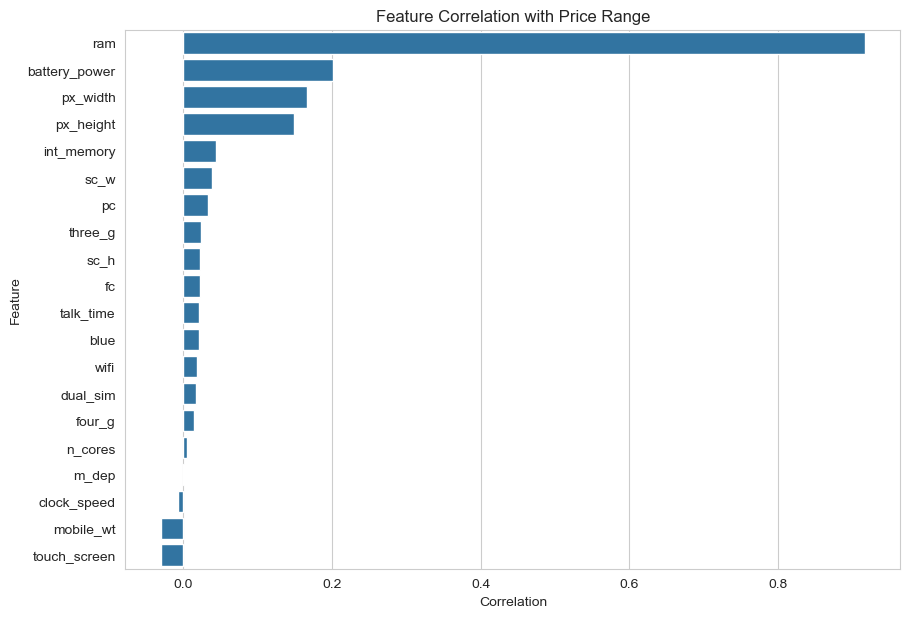

In [34]:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=price_correlation.values,
    y=price_correlation.index
)

plt.title("Feature Correlation with Price Range")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.show()

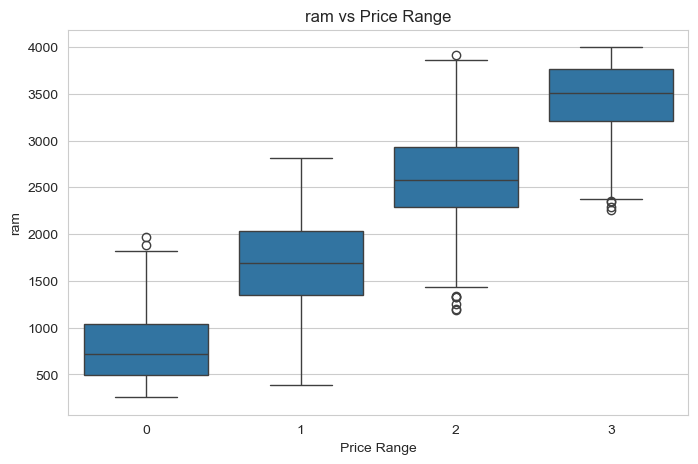

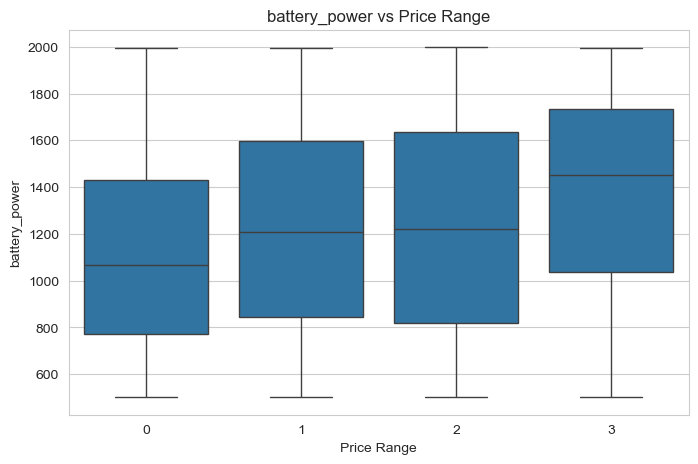

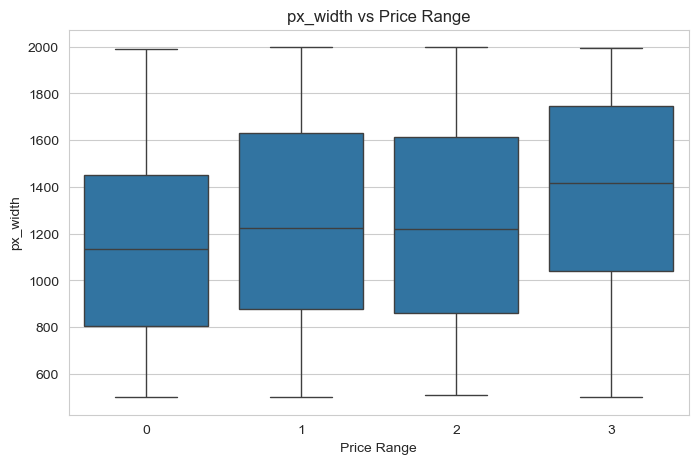

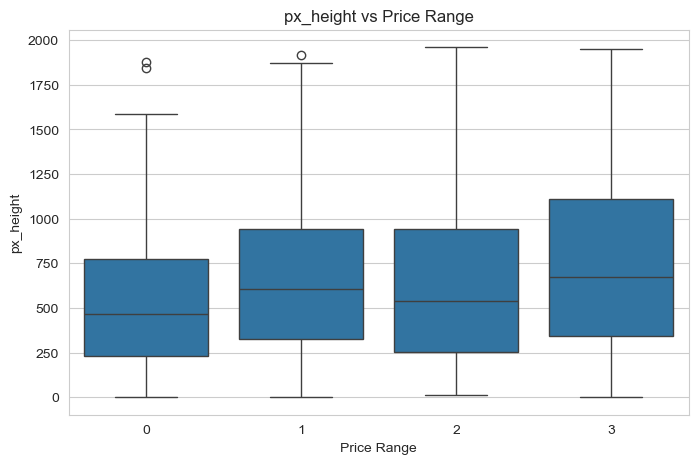

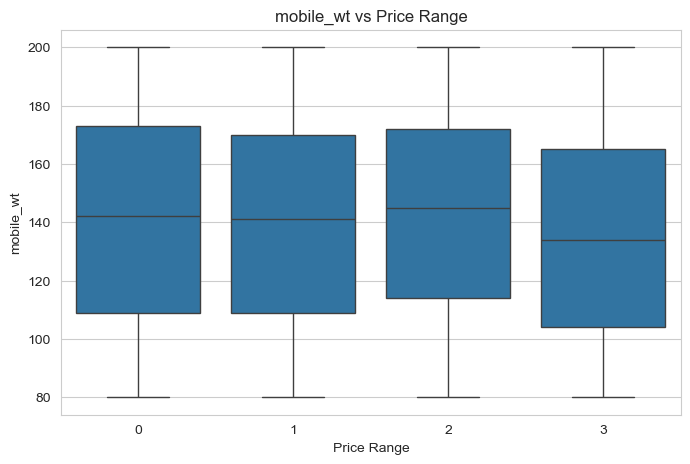

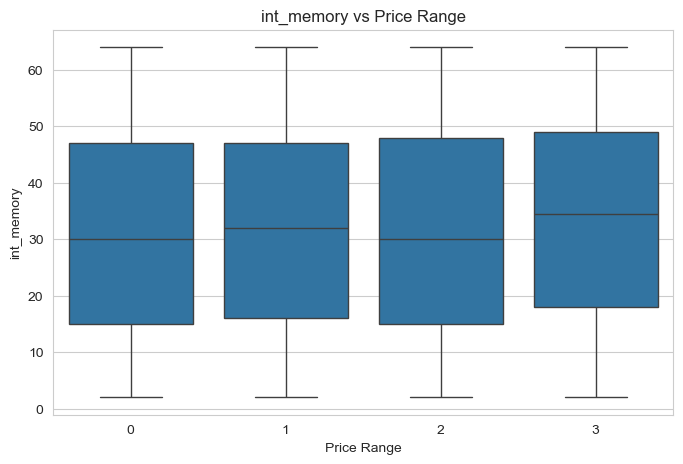

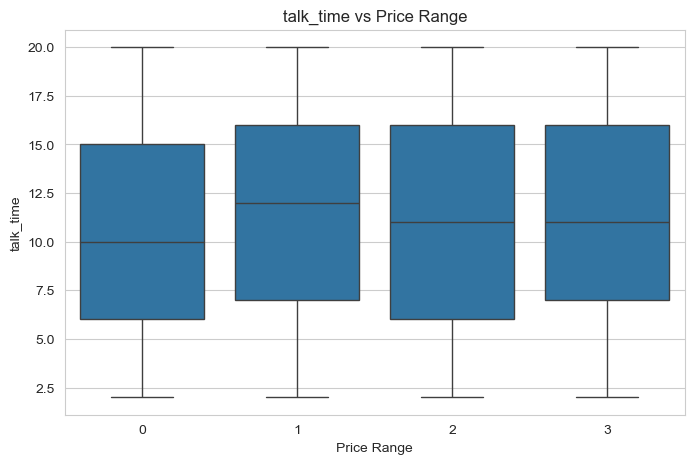

In [41]:
important_features = [
    "ram",
    "battery_power",
    "px_width",
    "px_height",
    "mobile_wt",
    "int_memory",
    "talk_time"
]

for feature in important_features:
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(
        data=df,
        x="price_range",
        y=feature
    )
    
    plt.title(f"{feature} vs Price Range")
    plt.xlabel("Price Range")
    plt.ylabel(feature)
    plt.show()

In [42]:
binary_features = [
    "blue",
    "dual_sim",
    "four_g",
    "three_g",
    "touch_screen",
    "wifi"
]

for feature in binary_features:
    print(f"\n{feature}")
    print(df[feature].value_counts().sort_index())


blue
blue
0    1010
1     990
Name: count, dtype: int64

dual_sim
dual_sim
0     981
1    1019
Name: count, dtype: int64

four_g
four_g
0     957
1    1043
Name: count, dtype: int64

three_g
three_g
0     477
1    1523
Name: count, dtype: int64

touch_screen
touch_screen
0     994
1    1006
Name: count, dtype: int64

wifi
wifi
0     986
1    1014
Name: count, dtype: int64


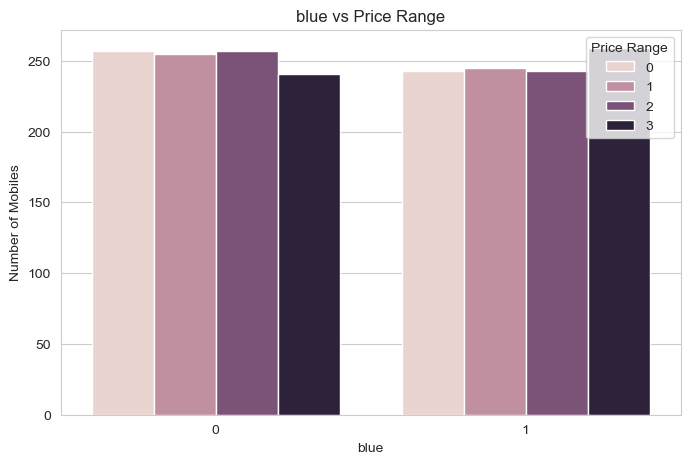

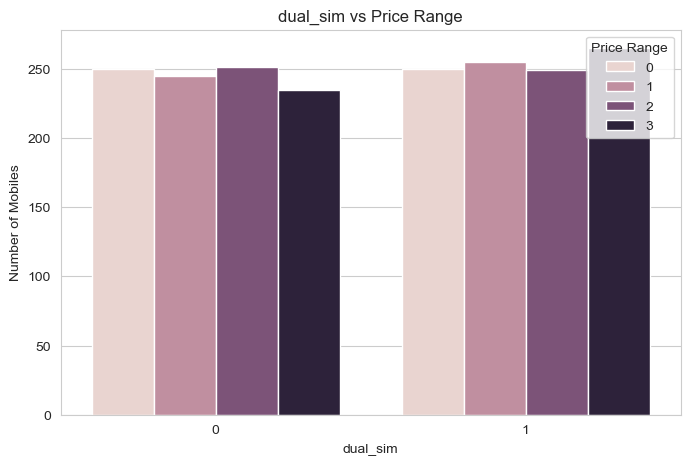

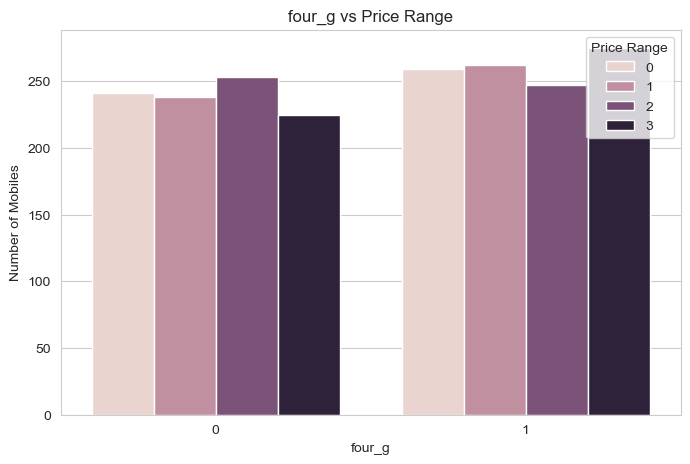

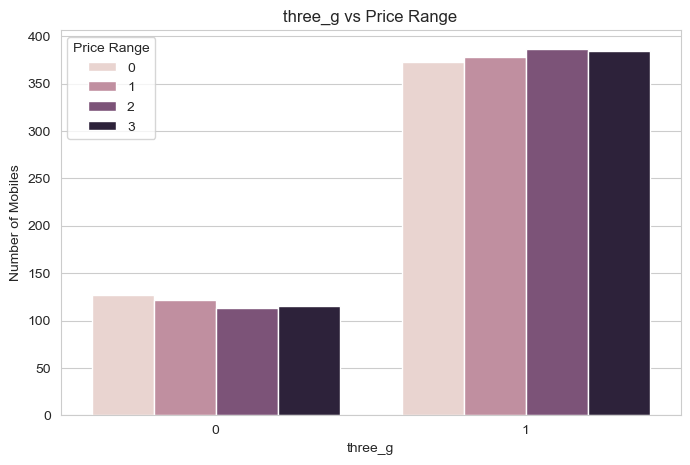

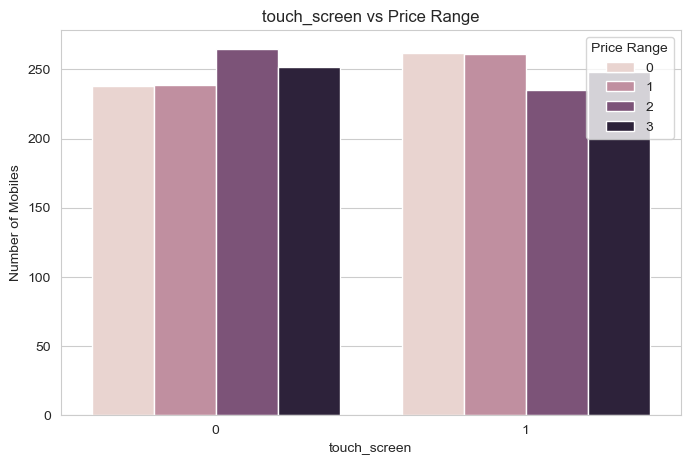

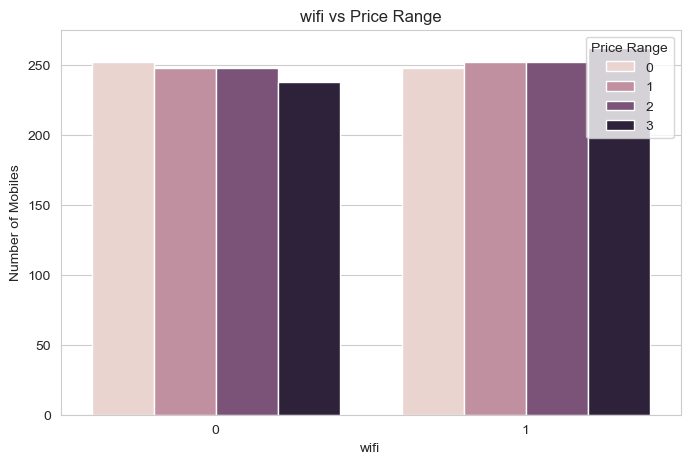

In [43]:
for feature in binary_features:
    plt.figure(figsize=(8, 5))
    
    sns.countplot(
        data=df,
        x=feature,
        hue="price_range"
    )
    
    plt.title(f"{feature} vs Price Range")
    plt.xlabel(feature)
    plt.ylabel("Number of Mobiles")
    plt.legend(title="Price Range")
    plt.show()

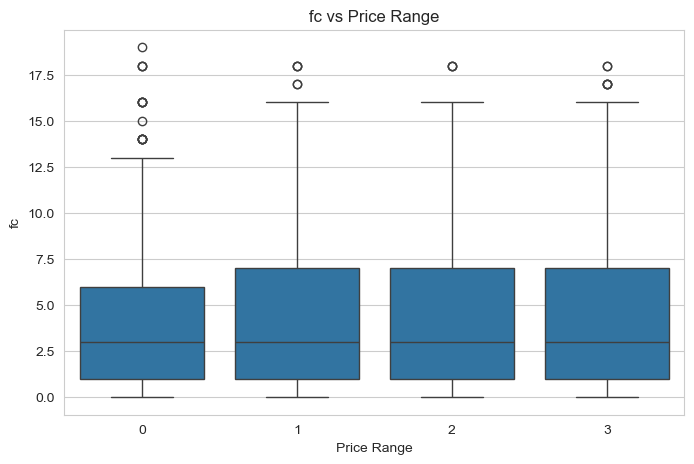

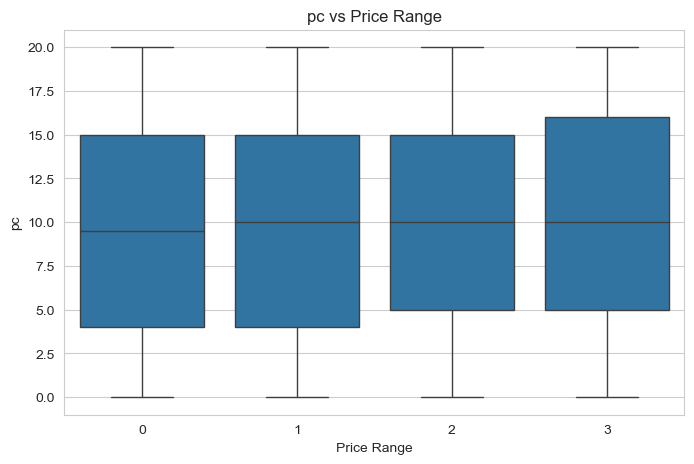

In [44]:
camera_features = ["fc", "pc"]

for feature in camera_features:
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(
        data=df,
        x="price_range",
        y=feature
    )
    
    plt.title(f"{feature} vs Price Range")
    plt.xlabel("Price Range")
    plt.ylabel(feature)
    plt.show()

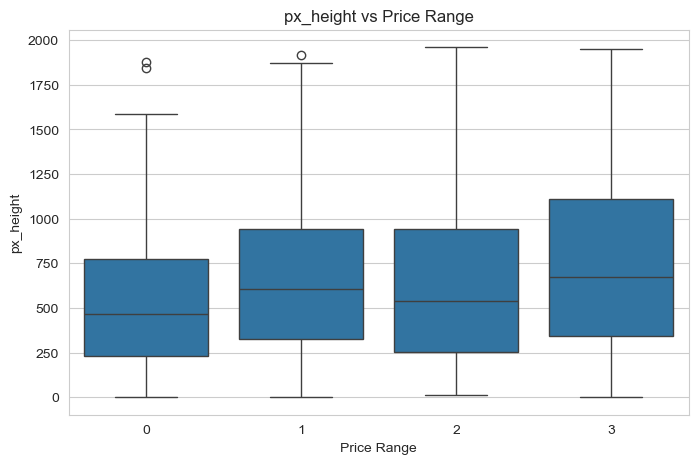

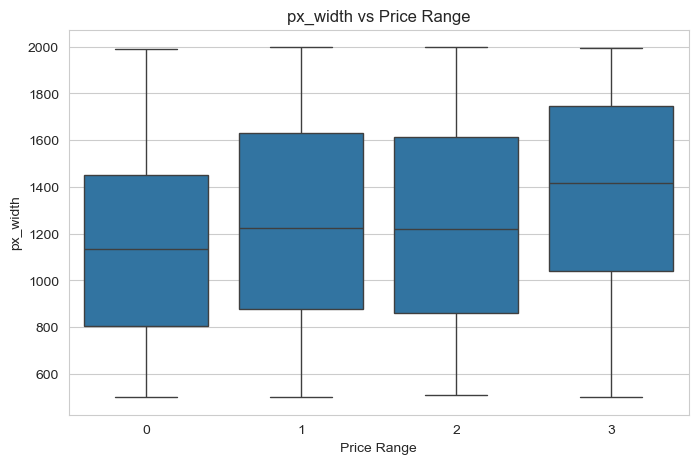

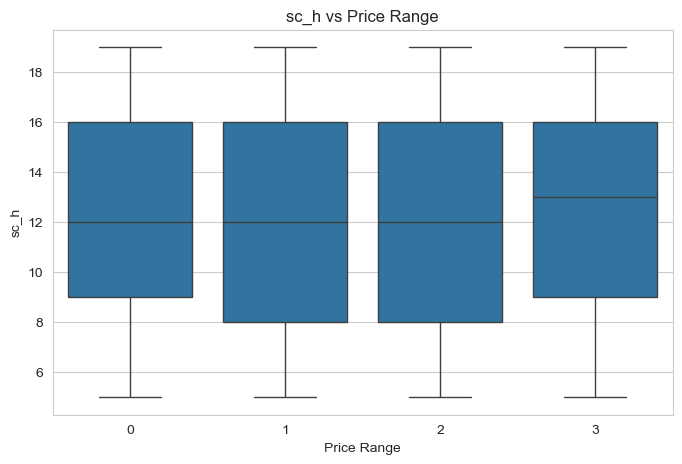

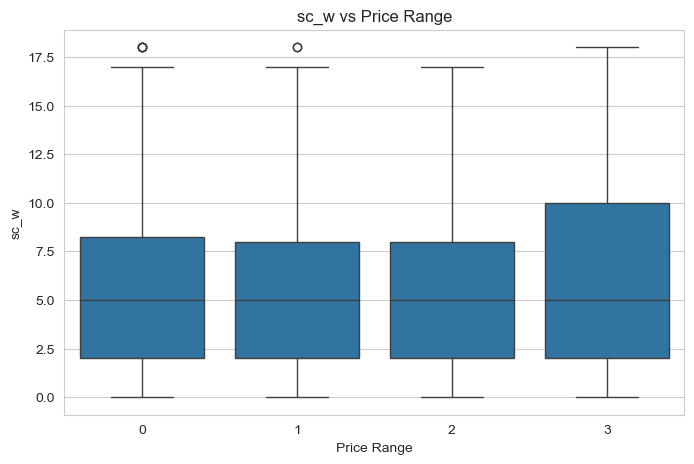

In [45]:
display_features = [
    "px_height",
    "px_width",
    "sc_h",
    "sc_w"
]

for feature in display_features:
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(
        data=df,
        x="price_range",
        y=feature
    )
    
    plt.title(f"{feature} vs Price Range")
    plt.xlabel("Price Range")
    plt.ylabel(feature)
    plt.show()

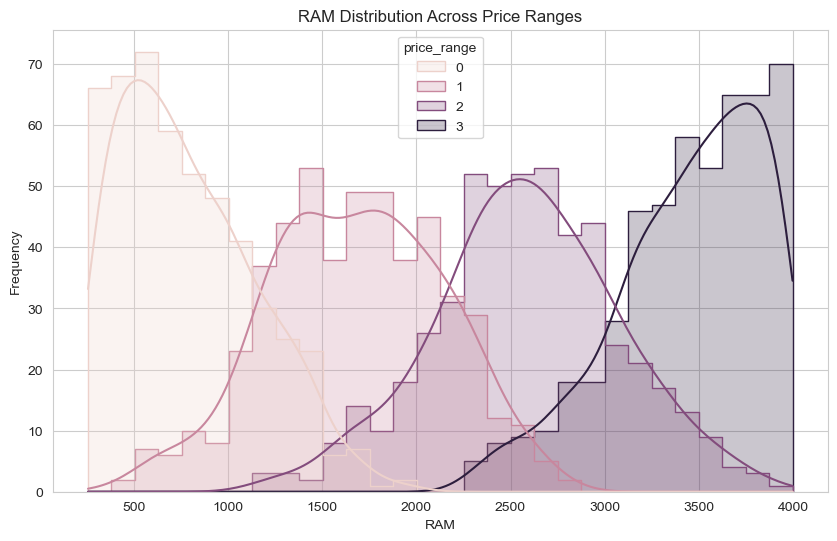

In [46]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="ram",
    hue="price_range",
    kde=True,
    bins=30,
    element="step"
)

plt.title("RAM Distribution Across Price Ranges")
plt.xlabel("RAM")
plt.ylabel("Frequency")
plt.show()

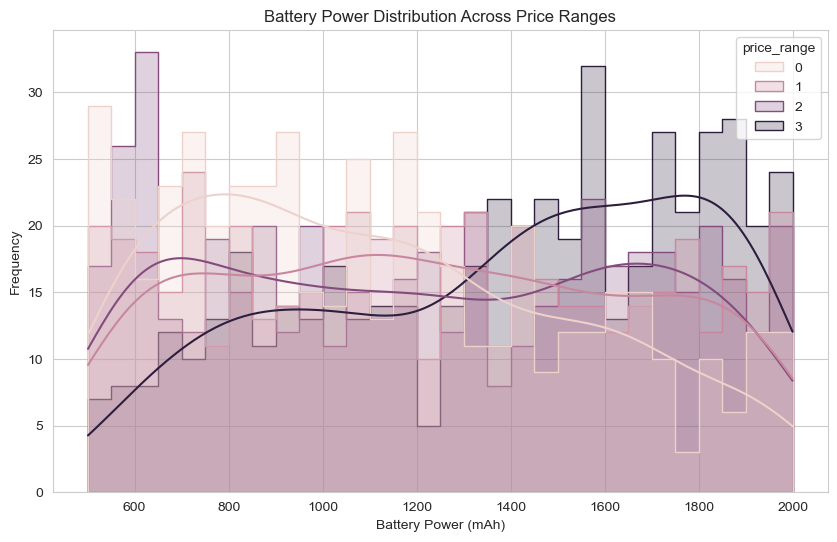

In [47]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="battery_power",
    hue="price_range",
    kde=True,
    bins=30,
    element="step"
)

plt.title("Battery Power Distribution Across Price Ranges")
plt.xlabel("Battery Power (mAh)")
plt.ylabel("Frequency")
plt.show()

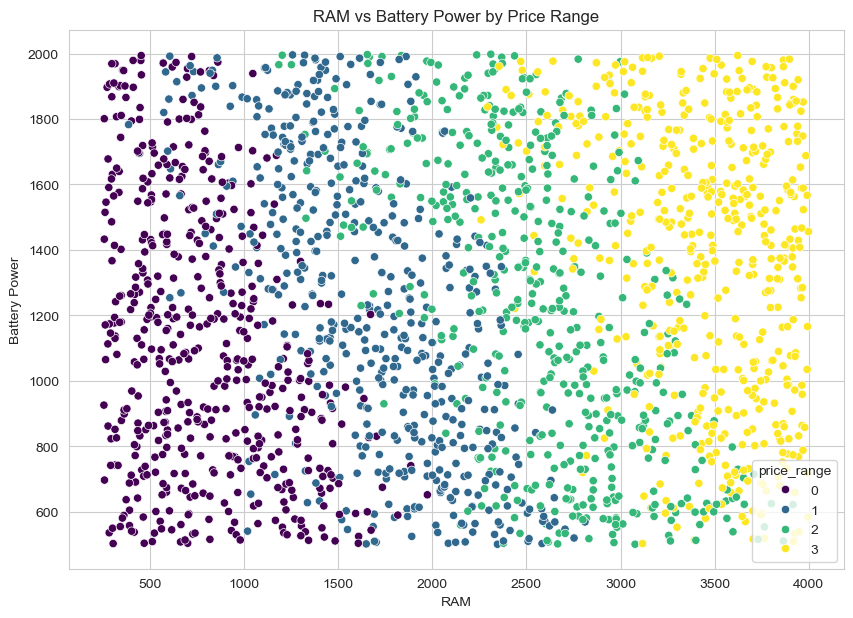

In [48]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="ram",
    y="battery_power",
    hue="price_range",
    palette="viridis"
)

plt.title("RAM vs Battery Power by Price Range")
plt.xlabel("RAM")
plt.ylabel("Battery Power")
plt.show()

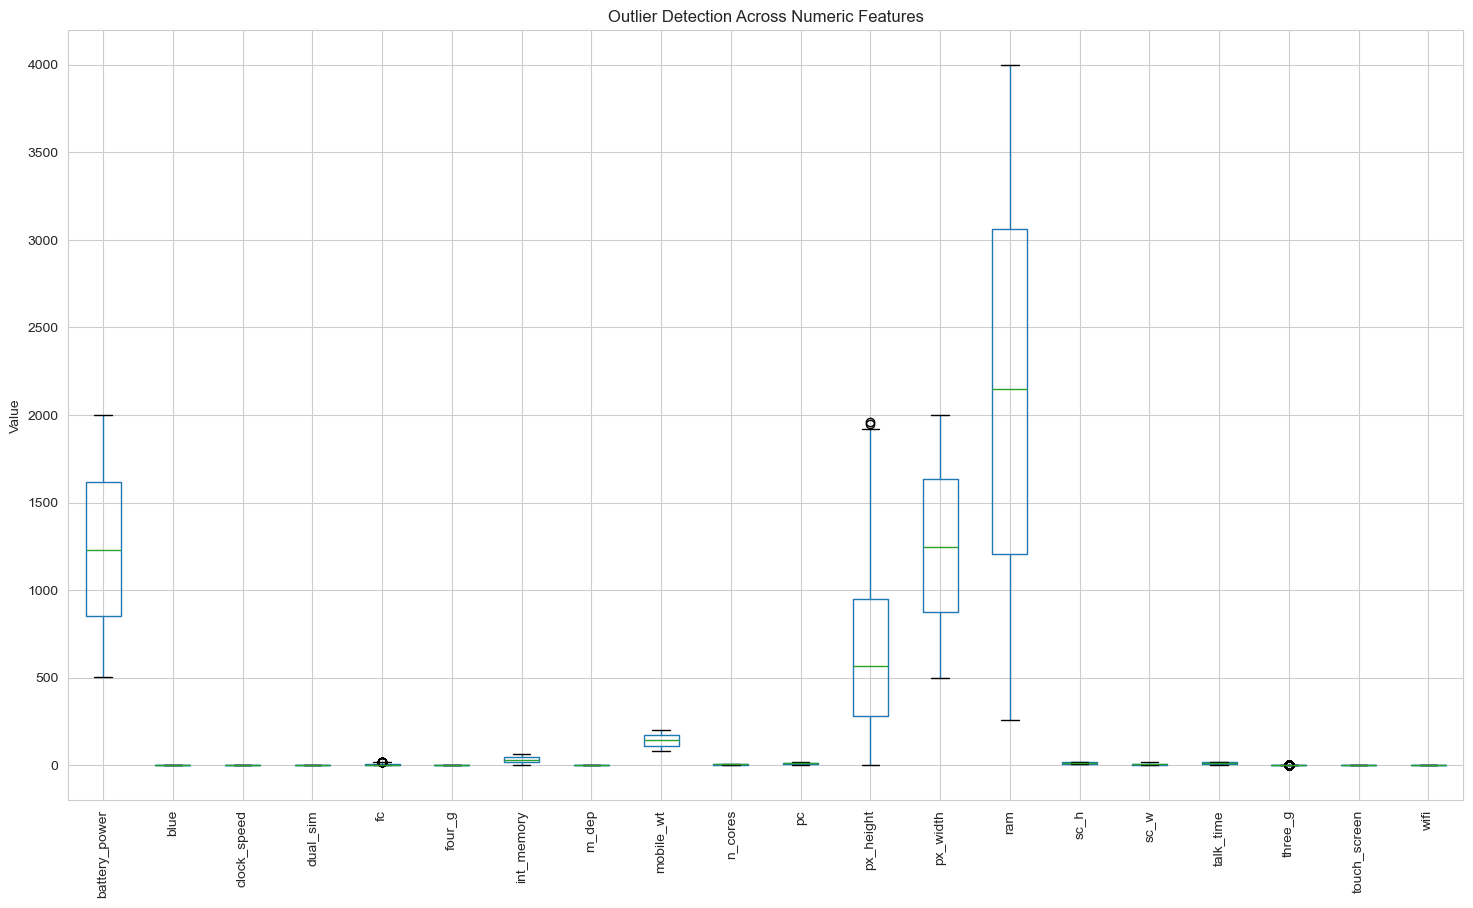

In [49]:
numeric_features = df.drop(columns=["price_range"]).select_dtypes(
    include=np.number
).columns

plt.figure(figsize=(18, 10))

df[numeric_features].boxplot(rot=90)

plt.title("Outlier Detection Across Numeric Features")
plt.ylabel("Value")
plt.show()

In [50]:
X = df.drop("price_range", axis=1)
y = df["price_range"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget classes:")
print(sorted(y.unique()))

Feature shape: (2000, 20)
Target shape: (2000,)

Features:
['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi']

Target classes:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training set: (1600, 20)
Testing set : (400, 20)

Training target distribution:
price_range
0    400
1    400
2    400
3    400
Name: count, dtype: int64

Testing target distribution:
price_range
0    100
1    100
2    100
3    100
Name: count, dtype: int64


In [52]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=7))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

print("Models defined:")
for name in models:
    print("-", name)

Models defined:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Extra Trees
- KNN
- SVM


In [53]:
results = []

trained_models = {}

for name, model in models.items():
    
    print(f"Training {name}...")
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    
    trained_models[name] = model
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

results_df = pd.DataFrame(results)

print("\nModel training completed!")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...
Training Extra Trees...
Training KNN...
Training SVM...

Model training completed!


In [54]:
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9650,0.9650,0.9650,0.9650
1,Gradient Boosting,0.9125,0.9124,0.9125,0.9123
2,SVM,0.8950,0.8969,0.8950,0.8956
3,Extra Trees,0.8825,0.8821,0.8825,0.8822
4,Random Forest,0.8800,0.8805,0.8800,0.8802
5,Decision Tree,0.8300,0.8319,0.8300,0.8302
6,KNN,0.5175,0.5267,0.5175,0.5199


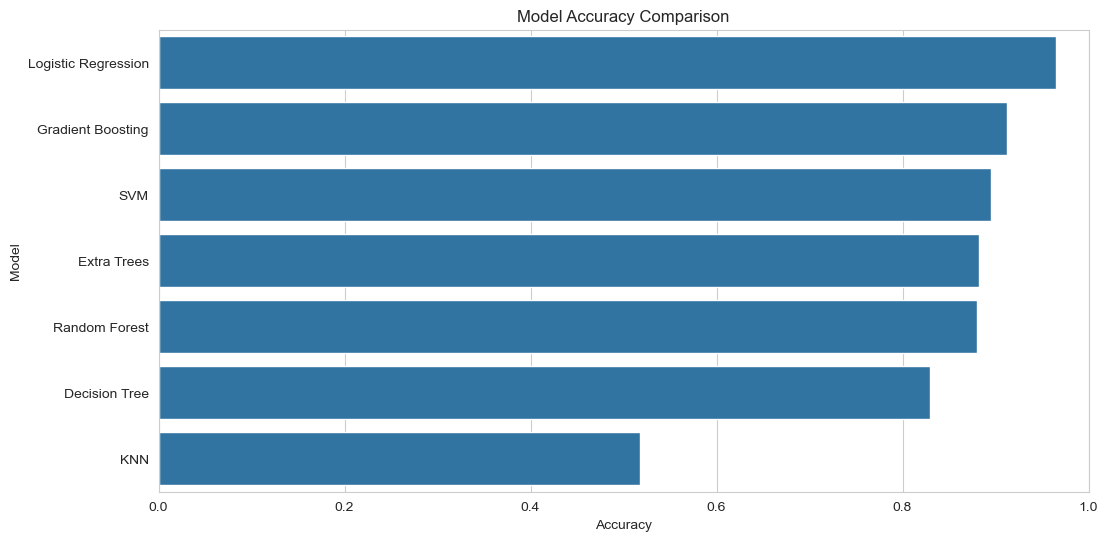

In [55]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

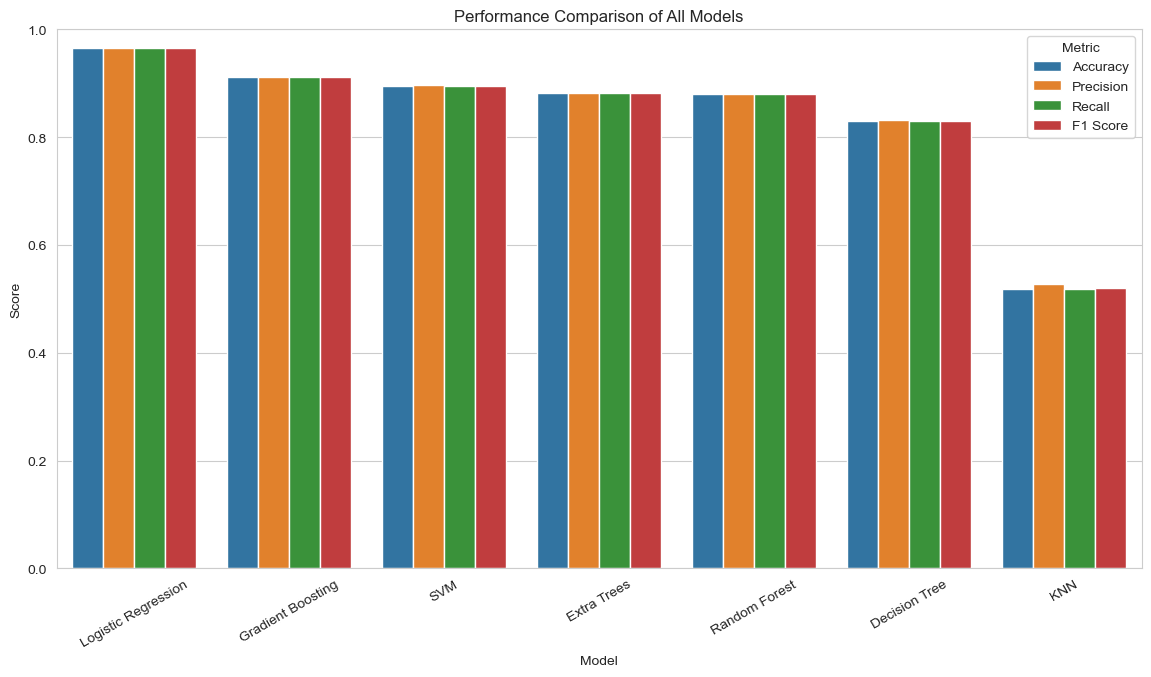

In [56]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

comparison_long = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of All Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.ylim(0, 1)

plt.show()

In [57]:
best_model_name = results_df.loc[
    results_df["Accuracy"].idxmax(),
    "Model"
]

best_accuracy = results_df["Accuracy"].max()

print("Best model based on test accuracy:")
print(best_model_name)

print(f"Accuracy: {best_accuracy:.4f}")
print(f"Accuracy (%): {best_accuracy * 100:.2f}%")

Best model based on test accuracy:
Logistic Regression
Accuracy: 0.9650
Accuracy (%): 96.50%


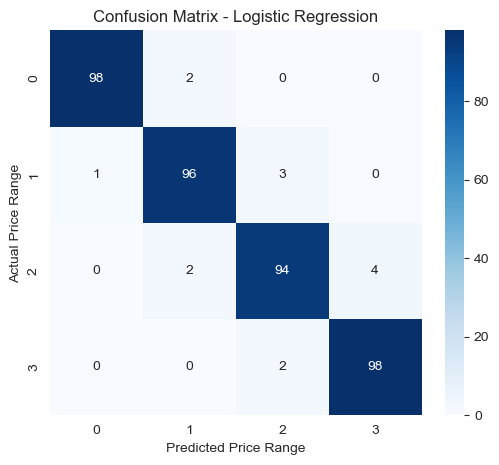

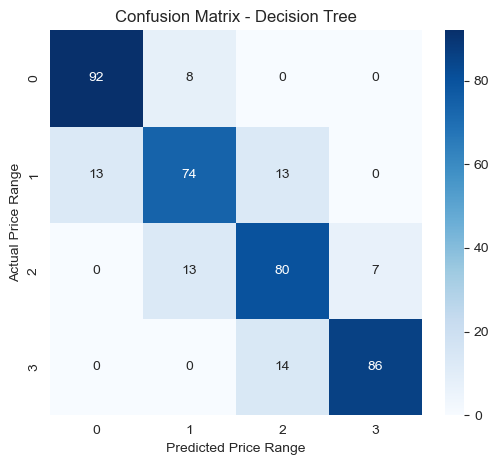

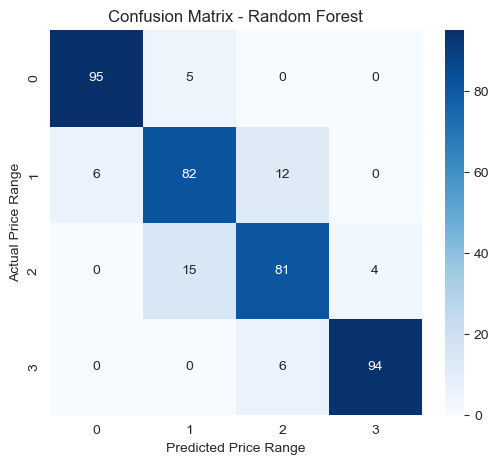

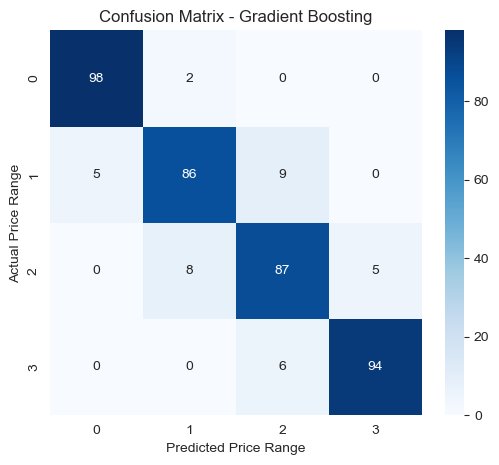

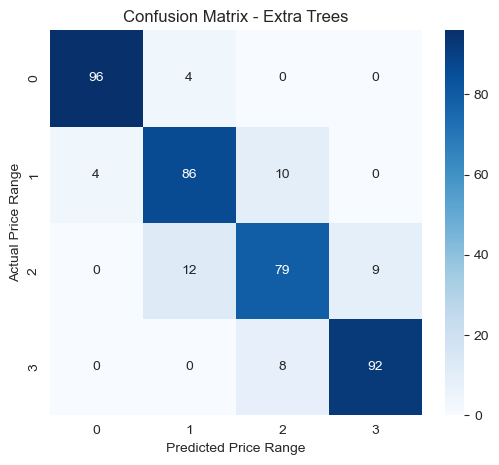

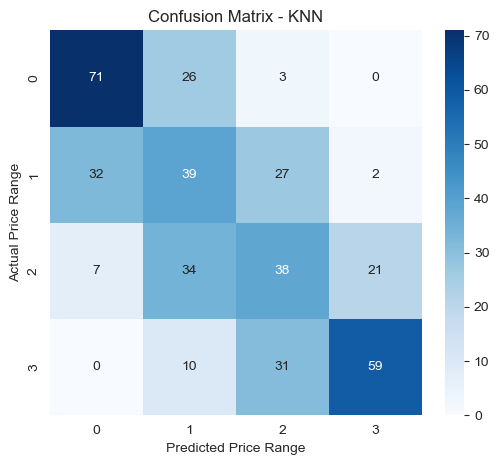

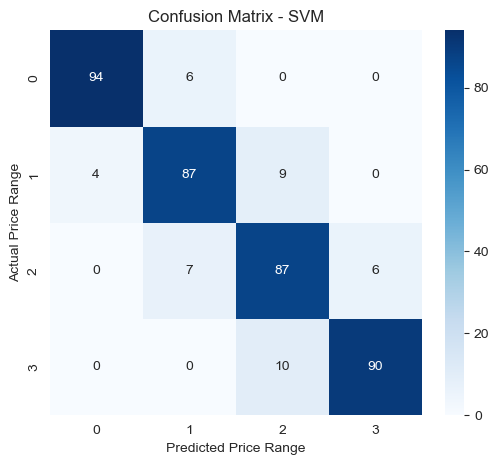

In [58]:
for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=sorted(y.unique()),
        yticklabels=sorted(y.unique())
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Price Range")
    plt.ylabel("Actual Price Range")
    plt.show()

In [59]:
for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            y_pred,
            digits=4
        )
    )

Logistic Regression
              precision    recall  f1-score   support

           0     0.9899    0.9800    0.9849       100
           1     0.9600    0.9600    0.9600       100
           2     0.9495    0.9400    0.9447       100
           3     0.9608    0.9800    0.9703       100

    accuracy                         0.9650       400
   macro avg     0.9650    0.9650    0.9650       400
weighted avg     0.9650    0.9650    0.9650       400

Decision Tree
              precision    recall  f1-score   support

           0     0.8762    0.9200    0.8976       100
           1     0.7789    0.7400    0.7590       100
           2     0.7477    0.8000    0.7729       100
           3     0.9247    0.8600    0.8912       100

    accuracy                         0.8300       400
   macro avg     0.8319    0.8300    0.8302       400
weighted avg     0.8319    0.8300    0.8302       400

Random Forest
              precision    recall  f1-score   support

           0     0.9406    

In [60]:
top_models = results_df.head(3)

print("Top 3 models based on test accuracy:")
display(
    top_models[
        ["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
    ]
)

Top 3 models based on test accuracy:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9650,0.965045,0.9650,0.964986
1,Gradient Boosting,0.9125,0.912431,0.9125,0.912295
2,SVM,0.8950,0.896860,0.8950,0.895631


In [61]:
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid_lr,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print("Best Parameters:")
print(grid_lr.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(f"{grid_lr.best_score_:.4f}")

Best Parameters:
{'model__C': 100}

Best Cross-Validation Accuracy:
0.9612


In [62]:
tuned_lr = grid_lr.best_estimator_

y_pred_lr = tuned_lr.predict(X_test)

tuned_lr_accuracy = accuracy_score(y_test, y_pred_lr)
tuned_lr_precision = precision_score(
    y_test,
    y_pred_lr,
    average="weighted"
)
tuned_lr_recall = recall_score(
    y_test,
    y_pred_lr,
    average="weighted"
)
tuned_lr_f1 = f1_score(
    y_test,
    y_pred_lr,
    average="weighted"
)

print("Tuned Logistic Regression Performance")
print("--------------------------------------")
print(f"Accuracy : {tuned_lr_accuracy:.4f}")
print(f"Precision: {tuned_lr_precision:.4f}")
print(f"Recall   : {tuned_lr_recall:.4f}")
print(f"F1 Score : {tuned_lr_f1:.4f}")

Tuned Logistic Regression Performance
--------------------------------------
Accuracy : 0.9825
Precision: 0.9826
Recall   : 0.9825
F1 Score : 0.9825


In [63]:
tuned_result = pd.DataFrame([{
    "Model": "Tuned Logistic Regression",
    "Accuracy": tuned_lr_accuracy,
    "Precision": tuned_lr_precision,
    "Recall": tuned_lr_recall,
    "F1 Score": tuned_lr_f1
}])

final_results = pd.concat(
    [results_df, tuned_result],
    ignore_index=True
)

final_results = final_results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(
    final_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Logistic Regression,0.9825,0.9826,0.9825,0.9825
1,Logistic Regression,0.9650,0.9650,0.9650,0.9650
2,Gradient Boosting,0.9125,0.9124,0.9125,0.9123
3,SVM,0.8950,0.8969,0.8950,0.8956
4,Extra Trees,0.8825,0.8821,0.8825,0.8822
5,Random Forest,0.8800,0.8805,0.8800,0.8802
6,Decision Tree,0.8300,0.8319,0.8300,0.8302
7,KNN,0.5175,0.5267,0.5175,0.5199


In [64]:
final_model_name = final_results.loc[
    0, "Model"
]

final_accuracy = final_results.loc[
    0, "Accuracy"
]

print("Final model selected based on test accuracy:")
print(final_model_name)

print(f"\nTest Accuracy: {final_accuracy:.4f}")
print(f"Test Accuracy (%): {final_accuracy * 100:.2f}%")

Final model selected based on test accuracy:
Tuned Logistic Regression

Test Accuracy: 0.9825
Test Accuracy (%): 98.25%


In [65]:
if final_model_name == "Tuned Logistic Regression":
    final_model = tuned_lr
else:
    final_model = trained_models[final_model_name]

final_predictions = final_model.predict(X_test)

print(classification_report(
    y_test,
    final_predictions,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9901    1.0000    0.9950       100
           1     0.9898    0.9700    0.9798       100
           2     0.9608    0.9800    0.9703       100
           3     0.9899    0.9800    0.9849       100

    accuracy                         0.9825       400
   macro avg     0.9826    0.9825    0.9825       400
weighted avg     0.9826    0.9825    0.9825       400



In [66]:
rf_model = trained_models["Random Forest"]

rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(rf_importance)

,Feature,Importance
0,ram,0.483102
1,battery_power,0.074234
2,px_width,0.057801
3,px_height,0.055615
4,mobile_wt,0.038501
5,int_memory,0.035762
6,talk_time,0.029916
7,pc,0.029594
8,sc_w,0.027995
9,clock_speed,0.027190


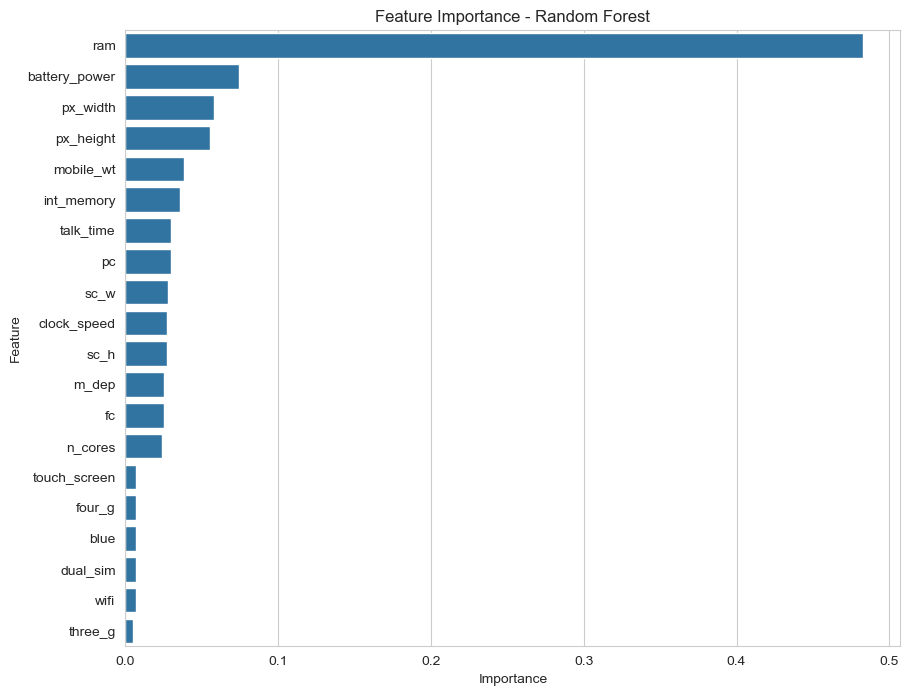

In [67]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [68]:
top_10_features = rf_importance.head(10)

print("Top 10 Important Features:")
display(top_10_features)

Top 10 Important Features:


,Feature,Importance
0,ram,0.483102
1,battery_power,0.074234
2,px_width,0.057801
3,px_height,0.055615
4,mobile_wt,0.038501
5,int_memory,0.035762
6,talk_time,0.029916
7,pc,0.029594
8,sc_w,0.027995
9,clock_speed,0.027190


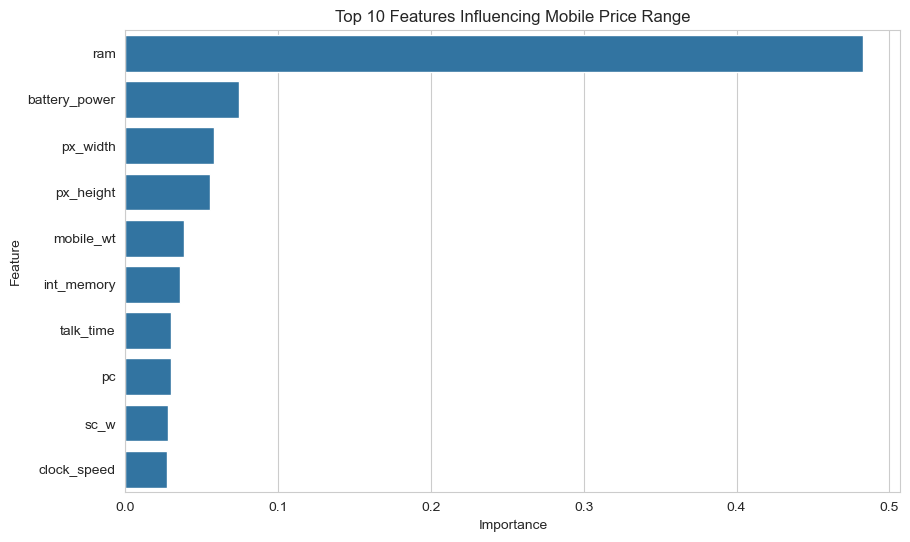

In [69]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Influencing Mobile Price Range")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [70]:
lr_model = tuned_lr.named_steps["model"]

lr_coefficients = pd.DataFrame(
    np.abs(lr_model.coef_).mean(axis=0),
    index=X.columns,
    columns=["Importance"]
)

lr_coefficients = lr_coefficients.sort_values(
    by="Importance",
    ascending=False
).reset_index()

lr_coefficients.columns = ["Feature", "Importance"]

display(lr_coefficients)

,Feature,Importance
0,ram,32.525860
1,battery_power,8.157207
2,px_width,4.807522
3,px_height,4.803481
4,mobile_wt,1.368146
5,int_memory,0.642533
6,wifi,0.513747
7,n_cores,0.394529
8,pc,0.346296
9,sc_h,0.337302


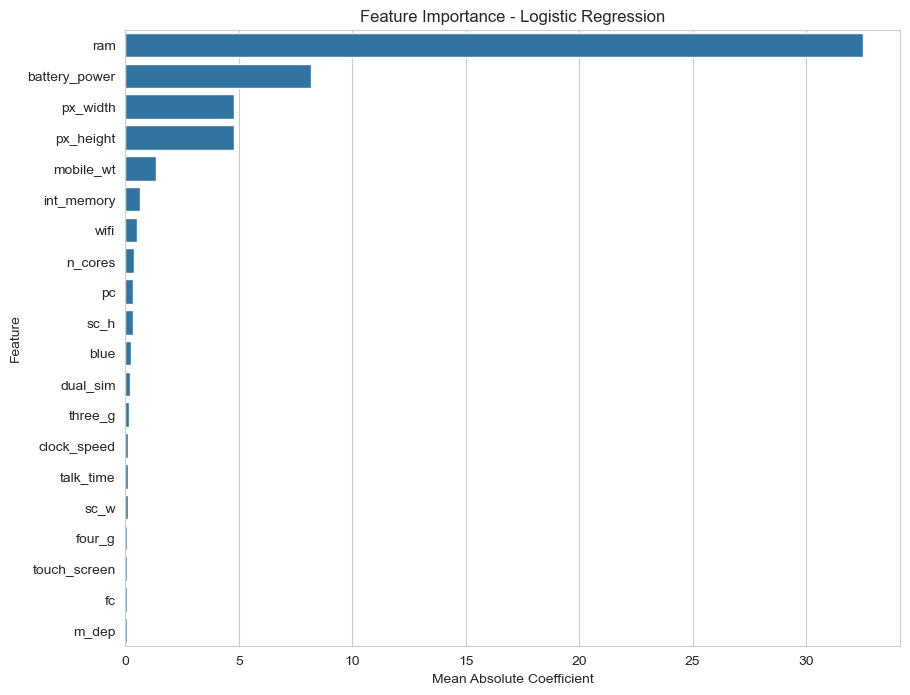

In [71]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=lr_coefficients,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Logistic Regression")
plt.xlabel("Mean Absolute Coefficient")
plt.ylabel("Feature")
plt.show()

In [72]:
feature_comparison = rf_importance.merge(
    lr_coefficients,
    on="Feature",
    suffixes=("_RandomForest", "_LogisticRegression")
)

feature_comparison["Average_Importance"] = (
    feature_comparison["Importance_RandomForest"] /
    feature_comparison["Importance_RandomForest"].max()
    +
    feature_comparison["Importance_LogisticRegression"] /
    feature_comparison["Importance_LogisticRegression"].max()
) / 2

feature_comparison = feature_comparison.sort_values(
    by="Average_Importance",
    ascending=False
).reset_index(drop=True)

display(feature_comparison)

,Feature,Importance_RandomForest,Importance_LogisticRegression,Average_Importance
0,ram,0.483102,32.525860,1.000000
1,battery_power,0.074234,8.157207,0.202226
2,px_width,0.057801,4.807522,0.133726
3,px_height,0.055615,4.803481,0.131401
4,mobile_wt,0.038501,1.368146,0.060880
5,int_memory,0.035762,0.642533,0.046890
6,pc,0.029594,0.346296,0.035952
7,sc_h,0.027058,0.337302,0.033190
8,talk_time,0.029916,0.128545,0.032939
9,n_cores,0.023648,0.394529,0.030540


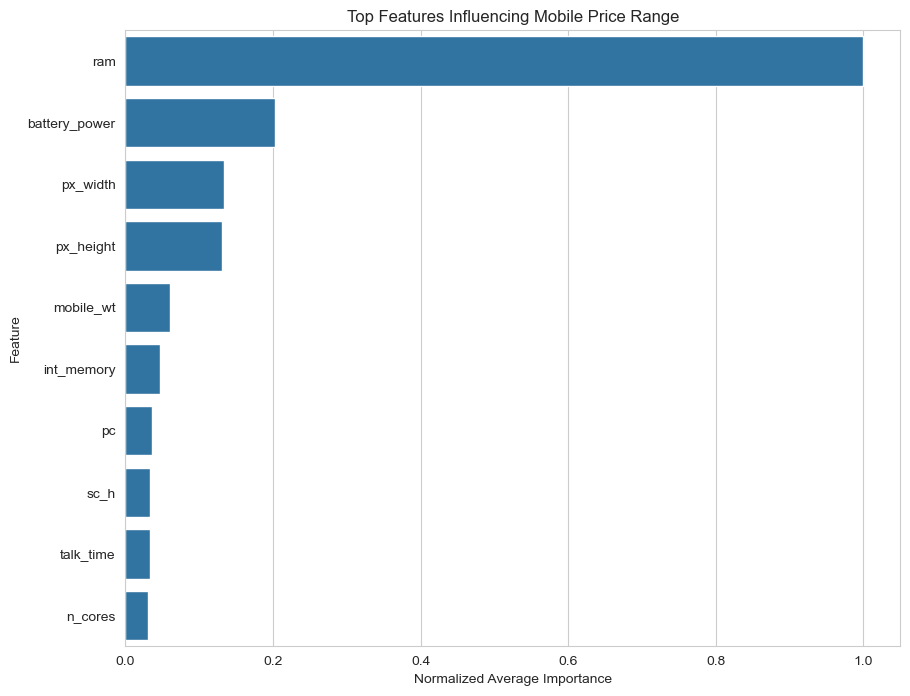

In [73]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_comparison.head(10),
    x="Average_Importance",
    y="Feature"
)

plt.title("Top Features Influencing Mobile Price Range")
plt.xlabel("Normalized Average Importance")
plt.ylabel("Feature")
plt.show()

In [74]:
prediction_comparison = pd.DataFrame({
    "Actual Price Range": y_test.values,
    "Predicted Price Range": final_predictions
})

display(prediction_comparison.head(20))

,Actual Price Range,Predicted Price Range
0,3,3
1,1,1
2,0,0
3,2,2
4,3,3
5,2,2
6,0,0
7,0,0
8,1,1
9,0,0


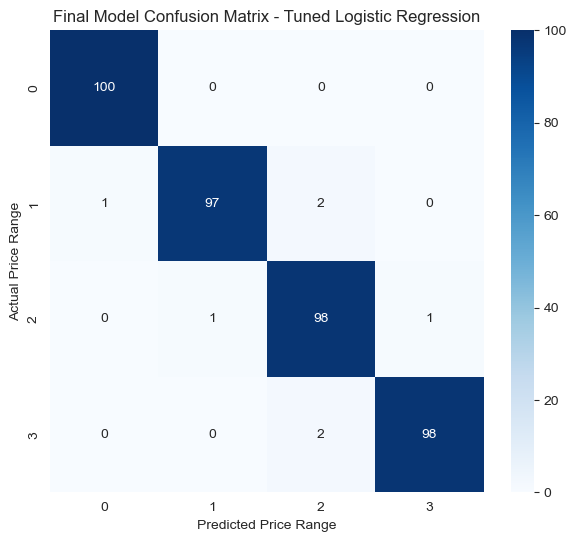

In [75]:
final_cm = confusion_matrix(
    y_test,
    final_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title(f"Final Model Confusion Matrix - {final_model_name}")
plt.xlabel("Predicted Price Range")
plt.ylabel("Actual Price Range")
plt.show()

In [76]:
import joblib

joblib.dump(final_model, "mobile_price_range_model.pkl")

print("Final model saved successfully!")
print("File: mobile_price_range_model.pkl")

Final model saved successfully!
File: mobile_price_range_model.pkl


In [77]:
def predict_price_range(mobile_data):
    """
    Predict the price range of a mobile phone.

    mobile_data should contain values for all 20 input features
    in the same order as the training dataset.
    """
    
    input_data = pd.DataFrame(
        [mobile_data],
        columns=X.columns
    )
    
    prediction = final_model.predict(input_data)[0]
    
    price_range_labels = {
        0: "Low Cost",
        1: "Medium Cost",
        2: "High Cost",
        3: "Very High Cost"
    }
    
    return prediction, price_range_labels[prediction]

In [78]:
sample_mobile = [
    1500,   # battery_power
    1,      # blue
    1.5,    # clock_speed
    1,      # dual_sim
    5,      # fc
    1,      # four_g
    32,     # int_memory
    0.5,    # m_dep
    150,    # mobile_wt
    8,      # n_cores
    12,     # pc
    800,    # px_height
    1400,   # px_width
    3000,   # ram
    15,     # sc_h
    8,      # sc_w
    15,     # talk_time
    1,      # three_g
    1,      # touch_screen
    1       # wifi
]

prediction, label = predict_price_range(sample_mobile)

print("Predicted Price Range:", prediction)
print("Category:", label)

Predicted Price Range: 3
Category: Very High Cost


In [79]:
sample_df = pd.DataFrame(
    [sample_mobile],
    columns=X.columns
)

display(sample_df)

print("\nPrediction:")
print(f"Price Range: {prediction}")
print(f"Category: {label}")

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1500,1,1.5,1,5,1,32,0.5,150,8,12,800,1400,3000,15,8,15,1,1,1



Prediction:
Price Range: 3
Category: Very High Cost


In [80]:
sample_df = pd.DataFrame(
    [sample_mobile],
    columns=X.columns
)

display(sample_df)

print("\nPrediction:")
print(f"Price Range: {prediction}")
print(f"Category: {label}")


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1500,1,1.5,1,5,1,32,0.5,150,8,12,800,1400,3000,15,8,15,1,1,1



Prediction:
Price Range: 3
Category: Very High Cost


In [81]:
final_results.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved successfully!")
print("File: model_comparison_results.csv")

Model comparison results saved successfully!
File: model_comparison_results.csv


In [82]:
feature_comparison.to_csv(
    "feature_importance_results.csv",
    index=False
)

print("Feature importance results saved successfully!")
print("File: feature_importance_results.csv")

Feature importance results saved successfully!
File: feature_importance_results.csv


In [86]:
import os

project_files = [
    "mobile_price_range_model.pkl",
    "model_comparison_results.csv",
    "feature_importance_results.csv"
]

print("Generated Project Files")
print("=" * 30)

for file in project_files:
    if os.path.exists(file):
        print(f" {file}")
    else:
        print(f" {file}")

Generated Project Files
 mobile_price_range_model.pkl
 model_comparison_results.csv
 feature_importance_results.csv


# Mobile Phone Price Range Prediction

## Project Overview

The objective of this project is to analyze mobile phone specifications and build a machine learning classification model that predicts the price range of a mobile phone.

The prediction is based on specifications such as battery power, RAM, internal memory, camera specifications, screen dimensions, connectivity features, processor cores, and other mobile characteristics.

The target variable `price_range` represents four price categories:

- 0 – Low Cost
- 1 – Medium Cost
- 2 – High Cost
- 3 – Very High Cost

## Business Problem

A new mobile company wants to compete with established smartphone companies. To support product planning and pricing decisions, the company needs to understand how different mobile specifications are associated with different price ranges.

Instead of predicting the exact selling price, this project develops a classification model that predicts the appropriate price range of a mobile phone.

The analysis can help the company understand which specifications are important for positioning mobile phones into different market segments.

## Data Analysis

The dataset contains mobile phone specifications along with the corresponding price range.

The analysis includes:

- Dataset structure and dimensions
- Data types
- Missing-value analysis
- Duplicate-value analysis
- Statistical summary
- Target-variable distribution
- Feature correlations
- Relationship between specifications and price range
- Outlier analysis
- Feature importance analysis

## Data Preparation

The dataset was checked for missing values and duplicate records before model development.

The target variable is:

`price_range`

The remaining mobile specifications are used as input features.

The data was divided into training and testing datasets using an 80:20 split. Stratified splitting was used to maintain the distribution of the price-range classes in both datasets.

StandardScaler was applied through pipelines for models that are sensitive to feature scale, such as Logistic Regression, KNN, and SVM.

## Machine Learning Models

Multiple classification algorithms were trained and evaluated:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. Extra Trees
6. K-Nearest Neighbors
7. Support Vector Machine

The models were compared using:

- Accuracy
- Precision
- Recall
- F1 Score

The model comparison allows the performance of different algorithms to be evaluated using the same test dataset.